In [1]:
META = {
    "id": "H0012",
    "title": "N-day high anchoring and Donchian breakouts",
    "status": "rejected",  # open | confirmed | rejected
    "result": "Rejected: no BO_N passes per coin (0/5 at p_adj<0.05; pooled BO_365 h7 +6.3% raw p 0.008, p_adj 0.13, n=43); NH365 adds nothing beyond z28 (pooled coef ~0, t +0.1; Spearman negative 3/5). Donchian ensemble net Sharpe 1.23 vs H0002 LF 1.30, maxDD -20% vs -28%, ~1/4 the turnover, but corr 0.87 with H0002 -> not a new strategy.",
    "hypotheses": ["H0002"],
}

# H0012 - N-day high anchoring and Donchian breakouts
**Hypothesis:** price LEVEL relative to a salient prior high (nearness to the N-day high) and the TIMING of fresh N-day closing-high breakouts predict higher forward returns, and carry information beyond H0002's 28-day return-sign momentum (z28).

**Papers**
- George, Hwang (2004), "The 52-Week High and Momentum Investing", JF 59(5) - https://www.bauer.uh.edu/tgeorge/papers/gh4-paper.pdf
- Jia, Simkins, Yan, Zhang, Zhao (2025), "Psychological Anchoring Effect and Cross Section of Cryptocurrency Returns", JBF - https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5386180
- Zarattini, Pagani, Barbon (2025), "Catching Crypto Trends; A Tactical Approach for Bitcoin and Altcoins", SFI RP 25-80 - https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5209907
- Padysak, Vojtko (2022), "Seasonality, Trend-following, and Mean reversion in Bitcoin" - https://papers.ssrn.com/sol3/papers.cfm?abstract_id=4081000

**Mechanism:** traders anchor on salient prior highs; good news that pushes price toward/through the high is under-reacted to (sellers at the anchor), then the price breaks out and continues. Breakouts also trigger mechanical trend-follower and short-stop flows.

**Spec.** OKX spot 1d BTC ETH XRP LTC SOL (2018-01+, SOL 2020-10+); Coinbase 1d BTC/ETH/LTC for 2015/16-2017.
Features at daily close t (past only): NH_N = close_t / max(high_{t-N+1..t}) (N=365 primary, 90 secondary);
fresh breakout BO_N = close_t > max(close_{t-N..t-1}) and no raw breakout in t-20..t-1; D = (close/SMA100 - 1)/sigma60;
H0002 control z28 = R28/(sigma60*sqrt(28)); Donchian ensemble P_t = mean over N in {20,55,120,250} of state_N
(enter when close > prior-N max close, exit when close < prior-N/2 min close; N/2 floored, 55 -> 27).
Targets: forward returns h in {1, 7, 28} days. Sub-periods 2018-2021 vs 2022+; Coinbase 2015-2017.
Bar `ts` = bar open time (UTC); close_t is known at ts + 1d and the forward return starts from that close.

In [2]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from qr import ohlcv, tables
from qr.db import ROOT
from qr.stats import event_table, compare, forward_returns, decile_table, hac_mean_test, bootstrap_diff_ci, adjust_pvalues
warnings.filterwarnings('ignore', message='only .* event samples')
pd.set_option('display.width', 220, 'display.max_columns', 40)

COINS = ['BTC', 'ETH', 'XRP', 'LTC', 'SOL']
CB_COINS = ['BTC', 'ETH', 'LTC']
BO_NS = [20, 55, 365]
HS = [1, 7, 28]
DON_NS = [20, 55, 120, 250]
PERIODS = {'full': ('2018-01-01', None), '2018-2021': ('2018-01-01', '2021-12-31'), '2022+': ('2022-01-01', None)}
CB_PERIOD = ('2015-01-01', '2017-12-31')
COST = 0.0023   # per unit of |d(P*w)| (0.23% spot round trip per unit); H0002 notebook used 0.115%/unit one-way
print(tables().table_name.tolist())

['benchmark', 'binance_delisted', 'binance_funding', 'binance_klines', 'binance_metrics', 'binance_um_1d', 'binance_um_funding', 'deribit_funding', 'deribit_futures', 'deribit_option_prints', 'dvol', 'funding', 'macro', 'ohlcv', 'ohlcv_coinbase']


## Data
Same loader as H0002: `qr.ohlcv`, Parquet fallback, full daily calendar (gaps stay NaN, never filled), only closed bars.

In [3]:
def load(coin, source='okx'):
    try:
        d = ohlcv(coin, '1d', source=source)
    except Exception:
        kind, sym = ('ohlcv_coinbase', f'{coin}-USD') if source == 'coinbase' else ('ohlcv', f'{coin}-USDT')
        p = ROOT / 'data' / kind / 'tf=1d' / f'symbol={sym}' / 'data.parquet'
        if not p.exists():
            return None
        d = pd.read_parquet(p).set_index('ts').sort_index()
    if d is None or d.empty:
        return None
    d.index = pd.to_datetime(d.index, utc=True)
    d = d[~d.index.duplicated()]
    d = d[d.index + pd.Timedelta('1D') <= pd.Timestamp.now(tz='UTC')]  # closed bars only
    return d.asfreq('D')

okx = {c: load(c) for c in COINS}
cb = {c: load(c, 'coinbase') for c in CB_COINS}
avail = pd.DataFrame({f'{src}:{c}': {'start': d.close.first_valid_index(), 'end': d.close.last_valid_index(),
                                     'bars': d.close.notna().sum(), 'gaps': int(d.close.isna().sum())}
                      for src, dd in [('okx', okx), ('cb', cb)] for c, d in dd.items() if d is not None}).T
print('OKX coins missing (skipped):', [c for c, d in okx.items() if d is None])
avail

OKX coins missing (skipped): []


,start,end,bars,gaps
okx:BTC,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:ETH,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:XRP,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:LTC,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:SOL,2020-10-01 00:00:00+00:00,2025-09-30 00:00:00+00:00,1826,0
cb:BTC,2015-07-20 00:00:00+00:00,2025-09-30 00:00:00+00:00,3726,0
cb:ETH,2016-05-18 00:00:00+00:00,2025-09-30 00:00:00+00:00,3421,2
cb:LTC,2016-08-17 00:00:00+00:00,2025-09-30 00:00:00+00:00,3331,1


## Features (known at daily close t only)
All rolling windows use bars <= t (prior-N windows use `shift(1)`, positive shifts only); full windows required (`min_periods = N`).
Forward returns are used only as the target.

In [4]:
def donchian_state(close, N):
    hi = close.shift(1).rolling(N, min_periods=N).max()
    lo = close.shift(1).rolling(N // 2, min_periods=N // 2).min()
    st = pd.Series(np.where(close > hi, 1.0, np.where(close < lo, 0.0, np.nan)), index=close.index)
    return st.ffill().fillna(0.0).where(hi.notna())   # 1 from entry bar until exit bar; NaN in warm-up

def features(d):
    close, high = d.close, d.high
    lr = np.log(close).diff()
    sigma = lr.rolling(60, min_periods=60).std()
    f = pd.DataFrame({'close': close, 'sigma': sigma})
    for N in [365, 90]:
        f[f'NH{N}'] = close / high.rolling(N, min_periods=N).max()
    for N in BO_NS:
        prior_max = close.shift(1).rolling(N, min_periods=N).max()
        raw = (close > prior_max).astype(float).where(prior_max.notna() & close.notna())
        recent = raw.shift(1).rolling(20, min_periods=20).sum()
        f[f'BO{N}'] = ((raw == 1) & (recent == 0)).where(recent.notna())  # NaN in warm-up
    f['D'] = (close / close.rolling(100, min_periods=100).mean() - 1) / sigma
    f['R28'] = close / close.shift(28) - 1
    f['z28'] = f.R28 / (sigma * np.sqrt(28))
    for N in DON_NS:
        f[f'S{N}'] = donchian_state(close, N)
    f['P'] = f[[f'S{N}' for N in DON_NS]].mean(axis=1, skipna=False)
    for h in HS:
        f[f'fwd{h}'] = forward_returns(close, h)   # target only
    return f

FEAT = {(src, c): features(d) for src, dd in [('okx', okx), ('cb', cb)] for c, d in dd.items() if d is not None}
FEAT[('okx', 'BTC')].dropna().tail(3).round(4)

,close,sigma,NH365,NH90,BO20,BO55,BO365,D,R28,z28,S20,S55,S120,S250,P,fwd1,fwd7,fwd28
ts,,,,,,,,,,,,,,,,,,
2025-08-31 00:00:00+00:00,108248.3,0.0162,0.8695,0.8695,False,False,False,-1.8807,-0.0521,-0.6071,0.0,0.0,1.0,1.0,0.5,0.0091,0.0267,0.0362
2025-09-01 00:00:00+00:00,109235.9,0.0162,0.8774,0.8774,False,False,False,-1.3421,-0.0506,-0.5881,0.0,0.0,1.0,1.0,0.5,0.0183,0.0259,0.0465
2025-09-02 00:00:00+00:00,111233.7,0.0163,0.8934,0.8934,False,False,False,-0.2525,-0.0253,-0.2940,0.0,0.0,1.0,1.0,0.5,0.0042,0.0028,0.0253


In [5]:
# How much of the new signals is already H0002 (z28 / R28>0)?
ov = {}
for (src, c), f in FEAT.items():
    if src != 'okx': continue
    g = f.dropna(subset=['NH365', 'D', 'z28'])
    ov[c] = {'corr(NH365,z28)': g.NH365.corr(g.z28), 'corr(D,z28)': g.D.corr(g.z28), 'corr(NH365,D)': g.NH365.corr(g.D),
             'corr(P,1[R28>0])': f.P.corr((f.R28 > 0).astype(float).where(f.R28.notna())),
             **{f'BO{N}: share with R28>0': f.loc[f[f'BO{N}'] == True, 'R28'].gt(0).mean() for N in BO_NS}}
pd.DataFrame(ov).T.round(3)

,"corr(NH365,z28)","corr(D,z28)","corr(NH365,D)","corr(P,1[R28>0])",BO20: share with R28>0,BO55: share with R28>0,BO365: share with R28>0
BTC,0.377,0.824,0.580,0.537,0.591,1.0,1.0
ETH,0.365,0.822,0.535,0.567,0.550,1.0,1.0
XRP,0.467,0.848,0.663,0.487,0.600,1.0,1.0
LTC,0.352,0.800,0.528,0.582,0.571,1.0,1.0
SOL,0.440,0.783,0.687,0.550,0.556,1.0,1.0


## Test 1 - Fresh N-day closing-high breakouts (event study)
Per coin, N in {20, 55, 365}, horizons 1/7/28d; baseline = all other valid bars of the same period (warm-up dropped). HAC lags = h.

In [6]:
counts = {}
for (src, c), f in FEAT.items():
    for N in BO_NS:
        e = f[f'BO{N}'] == True
        counts[(src, c, f'BO{N}')] = e.groupby(f.index.year).sum()
CNT = pd.DataFrame(counts).T.fillna(0).astype(int)
CNT['total'] = CNT.sum(axis=1)
CNT

ts             2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  total
okx BTC BO20      0     0     0     4     4     5     6     8     5     7     5     44
        BO55      0     0     0     2     2     5     4     2     4     3     4     26
        BO365     0     0     0     0     1     2     3     0     2     3     4     15
    ETH BO20      0     0     0     4     6     5     3     6     7     7     2     40
        BO55      0     0     0     1     3     4     3     2     5     3     2     23
        BO365     0     0     0     0     0     2     2     0     2     1     1      8
    XRP BO20      0     0     0     5     6     6     6     6     6     5     5     45
        BO55      0     0     0     1     3     3     4     1     5     4     3     24
        BO365     0     0     0     0     0     1     1     0     1     1     2      6
    LTC BO20      0     0     0     6     4     7     4     5     7     4     5     42
        BO55      0     0     0     0     2     4     4     2     5     3     3     23
        BO365     0     0     0     0     1     2     2     0     1     1     1      8
    SOL BO20      0     0     0     0     0     0     5     5     9     4     4     27
        BO55      0     0     0     0     0     0     4     2     5     3     4     18
        BO365     0     0     0     0     0     0     1     0     2     2     1      6
cb  BTC BO20      3     5     4     5     4     5     7     8     5     7     5     58
        BO55      2     3     4     2     2     5     4     2     4     3     4     35
        BO365     0     1     4     0     1     2     3     0     2     3     4     20
    ETH BO20      0     2     6     4     7     5     3     6     7     7     2     49
        BO55      0     1     5     1     4     4     3     2     5     3     2     30
        BO365     0     0     1     0     0     2     2     0     2     1     1      9
    LTC BO20      0     2     6     7     4     7     4     5     7     4     5     51
        BO55      0     1     4     0     2     4     4     2     5     3     3     28
        BO365     0     0     1     0     1     2     2     0     1     1     1      9

In [7]:
rows = []
def run_event(src, c, N, pname, start, end):
    f = FEAT[(src, c)].loc[start:end]
    f = f[f[f'BO{N}'].notna() & f.close.notna()]
    if len(f) < 200:
        return
    et = event_table(f.close, f[f'BO{N}'].astype(bool), horizons=HS)
    for h, r in et.iterrows():
        rows.append({'test': 'event', 'source': src, 'coin': c, 'variant': f'BO_{N}', 'period': pname, 'horizon': h,
                     'n_event': int(r.n_event), 'n_base': int(r.n_base), 'diff': r['diff'], 'hac_t': r.hac_t,
                     'hac_p': r.hac_p, 'boot_lo': r.boot_ci_lo, 'boot_hi': r.boot_ci_hi})

for c in COINS:
    if okx[c] is None: continue
    for N in BO_NS:
        for pname, (s, e) in PERIODS.items():
            run_event('okx', c, N, pname, s, e)
for c in CB_COINS:
    if cb[c] is None: continue
    for N in BO_NS:
        run_event('cb', c, N, '2015-2017', *CB_PERIOD)
EV = pd.DataFrame(rows)
EV.query("period=='full' and source=='okx'").pivot_table(index=['variant', 'coin'], columns='horizon',
        values=['n_event', 'diff', 'hac_p']).round(4)

diff                   hac_p                 n_event            
horizon           1       7       28      1       7       28      1     7     28
variant coin                                                                    
BO_20   BTC   0.0075  0.0160 -0.0009  0.0937  0.2245  0.9710    44.0  44.0  43.0
        ETH  -0.0003  0.0309  0.0476  0.9578  0.0328  0.1869    40.0  40.0  40.0
        LTC  -0.0055 -0.0043  0.0369  0.3383  0.7569  0.2765    42.0  42.0  41.0
        SOL   0.0070  0.0363  0.0257  0.5760  0.3058  0.6872    27.0  27.0  27.0
        XRP  -0.0013 -0.0054  0.0726  0.9094  0.7599  0.2259    45.0  45.0  44.0
BO_365  BTC   0.0025  0.0051  0.0184  0.6126  0.7802  0.6322    15.0  15.0  15.0
        ETH   0.0124  0.0869  0.1372  0.3424  0.0220  0.0385     8.0   8.0   8.0
        LTC   0.0096  0.0153  0.0844  0.6658  0.7347  0.4237     8.0   8.0   8.0
        SOL   0.0410  0.0752  0.2114  0.0148  0.0032  0.0623     6.0   6.0   6.0
        XRP   0.0330  0.2283  0.3246  0.4595  0.0523  0.2429     6.0   6.0   6.0
BO_55   BTC   0.0077  0.0150  0.0152  0.4282  0.3503  0.6037    26.0  26.0  26.0
        ETH   0.0014  0.0494  0.1086  0.8947  0.0163  0.0239    23.0  23.0  23.0
        LTC   0.0001  0.0082  0.1084  0.9948  0.7332  0.0152    23.0  23.0  23.0
        SOL   0.0032  0.0819  0.2793  0.8081  0.0573  0.0748    18.0  18.0  18.0
        XRP   0.0188  0.0818  0.1280  0.4013  0.1255  0.1830    24.0  24.0  24.0

In [8]:
# sign check of diff across periods (h=7 and h=28)
EV.query('horizon in [7, 28]').pivot_table(index=['variant', 'coin'], columns=['horizon', 'period'], values='diff').round(4)

horizon             7                                   28                          
period       2015-2017 2018-2021   2022+    full 2015-2017 2018-2021   2022+    full
variant coin                                                                        
BO_20   BTC    -0.0092    0.0238  0.0104  0.0160    0.0461   -0.0026  0.0001 -0.0009
        ETH     0.0610    0.0405  0.0238  0.0309    0.1084    0.0399  0.0544  0.0476
        LTC    -0.1354    0.0077 -0.0165 -0.0043   -0.2387    0.0419  0.0278  0.0369
        SOL        NaN    0.1947  0.0234  0.0363       NaN    0.5511 -0.0037  0.0257
        XRP        NaN   -0.0131  0.0023 -0.0054       NaN    0.0825  0.0778  0.0726
BO_365  BTC     0.0491   -0.0332  0.0313  0.0051    0.0859   -0.0183  0.0429  0.0184
        ETH     0.0280    0.1201  0.0498  0.0869    0.7699    0.0874  0.1661  0.1372
        LTC        NaN    0.0415 -0.0373  0.0153       NaN    0.2045 -0.1533  0.0844
        SOL        NaN       NaN  0.0868  0.0752       NaN       NaN  0.2320  0.2114
        XRP        NaN    0.4624  0.1120  0.2283       NaN    0.3807  0.2963  0.3246
BO_55   BTC     0.0661    0.0014  0.0282  0.0150    0.0883   -0.0088  0.0352  0.0152
        ETH     0.0609    0.0375  0.0606  0.0494    0.2969    0.1277  0.0882  0.1086
        LTC    -0.0718    0.0579 -0.0295  0.0082    0.2574    0.1797  0.0540  0.1084
        SOL        NaN    0.1736  0.0541  0.0819       NaN    0.8488  0.0978  0.2793
        XRP        NaN    0.1158  0.0529  0.0818       NaN    0.1643  0.0930  0.1280

In [9]:
# Pooled event test (all OKX coins stacked, time-sorted): BO_365 n per coin is < 30, so pool them.
# Baseline = non-event bars of all coins; HAC lags = h x n_coins (overlap spans h days and ~n_coins rows share a date).
pool = []
for N in BO_NS:
    for pname, (s, e) in PERIODS.items():
        a, b = {h: [] for h in HS}, {h: [] for h in HS}
        ncoins = 0
        for c in COINS:
            f = FEAT[('okx', c)].loc[s:e]
            f = f[f[f'BO{N}'].notna() & f.close.notna()]
            if len(f) < 200: continue
            ncoins += 1
            ev_ = f[f'BO{N}'] == True
            for h in HS:
                y = forward_returns(f.close, h)
                a[h].append(y[ev_]); b[h].append(y[~ev_])
        for h in HS:
            r = compare(pd.concat(a[h]).dropna(), pd.concat(b[h]).dropna(), hac_lags=h * ncoins, n_boot=2000)
            pool.append({'test': 'event_pooled', 'source': 'okx', 'coin': 'POOLED', 'variant': f'BO_{N}', 'period': pname, 'horizon': h,
                         'n_event': int(r['n_event']), 'n_base': int(r['n_base']), 'diff': r['diff'], 'hac_t': r['hac_t'], 'hac_p': r['hac_p'],
                         'boot_lo': r['boot_ci_lo'], 'boot_hi': r['boot_ci_hi'], 'median_event': r['median_event'], 'hit_event': r['hit_rate_event']})
EVP = pd.DataFrame(pool)
EVP.pivot_table(index=['variant', 'horizon'], columns='period', values=['n_event', 'diff', 'hac_p']).round(4)

diff                     hac_p                   n_event              
period          2018-2021   2022+    full 2018-2021   2022+    full 2018-2021  2022+   full
variant horizon                                                                            
BO_20   1          0.0075 -0.0037  0.0011    0.2585  0.3922  0.7771      86.0  112.0  198.0
        7          0.0194  0.0090  0.0126    0.1987  0.4429  0.1752      85.0  112.0  198.0
        28         0.0564  0.0304  0.0376    0.2527  0.3470  0.1794      84.0  109.0  195.0
BO_365  1          0.0153  0.0155  0.0153    0.2990  0.1745  0.0848      17.0   25.0   43.0
        7          0.0833  0.0502  0.0630    0.0220  0.1079  0.0084      17.0   25.0   43.0
        28         0.1178  0.1176  0.1209    0.0358  0.2183  0.0461      17.0   25.0   43.0
BO_55   1          0.0138  0.0012  0.0066    0.3005  0.8268  0.3162      49.0   65.0  114.0
        7          0.0626  0.0332  0.0457    0.0447  0.0941  0.0099      49.0   65.0  114.0
        28         0.1806  0.0743  0.1209    0.0287  0.1413  0.0122      49.0   65.0  114.0

## Test 1b - Do breakouts add beyond H0002? Partial regression fwd_h ~ BO_N + z28
Per coin, OKX full period, HAC maxlags = h. BO coefficient = mean excess forward return on breakout days after controlling for z28.

In [10]:
def hac_ols(y, X, lags):
    d = pd.concat([y.rename('y'), X], axis=1).dropna()
    fit = sm.OLS(d.y, sm.add_constant(d.drop(columns='y'), has_constant='add')).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return fit, len(d)

prow = []
for c in COINS:
    f = FEAT[('okx', c)]
    for N in BO_NS:
        for h in [7, 28]:
            fit, n = hac_ols(f[f'fwd{h}'], pd.DataFrame({'BO': f[f'BO{N}'].astype(float), 'z28': f.z28}), h)
            prow.append({'test': 'bo_partial', 'source': 'okx', 'coin': c, 'variant': f'BO_{N}|z28', 'period': 'full', 'horizon': h,
                         'n_event': int((f[f'BO{N}'] == True).sum()), 'n_base': n, 'diff': fit.params['BO'], 'hac_t': fit.tvalues['BO'],
                         'hac_p': fit.pvalues['BO'], 'boot_lo': np.nan, 'boot_hi': np.nan})
BOP = pd.DataFrame(prow)
BOP.pivot_table(index=['variant', 'coin'], columns='horizon', values=['diff', 'hac_t', 'hac_p']).round(4)

diff           hac_p           hac_t        
horizon              7       28      7       28      7       28
variant    coin                                                
BO_20|z28  BTC   0.0170  0.0025  0.2072  0.9187  1.2612  0.1020
           ETH   0.0313  0.0449  0.0317  0.1981  2.1483  1.2870
           LTC  -0.0049  0.0344  0.7314  0.3132 -0.3433  1.0086
           SOL   0.0419  0.0360  0.2463  0.6352  1.1595  0.4745
           XRP  -0.0061  0.0690  0.7374  0.2981 -0.3353  1.0405
BO_365|z28 BTC  -0.0023 -0.0122  0.8975  0.7736 -0.1288 -0.2877
           ETH   0.0772  0.1215  0.0444  0.0836  2.0101  1.7301
           LTC   0.0121  0.0791  0.7911  0.3830  0.2648  0.8724
           SOL   0.0558  0.1698  0.0348  0.1205  2.1112  1.5528
           XRP   0.2115  0.3822  0.0675  0.1853  1.8283  1.3247
BO_55|z28  BTC   0.0107 -0.0014  0.5114  0.9653  0.6566 -0.0435
           ETH   0.0446  0.1046  0.0312  0.0269  2.1547  2.2135
           LTC   0.0056  0.1020  0.8169  0.0287  0.2316  2.1876
           SOL   0.0692  0.2454  0.1236  0.1497  1.5397  1.4407
           XRP   0.0762  0.1562  0.1496  0.1220  1.4408  1.5463

## Test 2 - Quintiles of NH_365 and of MA distance D vs forward returns (h = 7, 28)
Expect increasing. Spearman p ignores overlapping windows (indicative only). Q5-Q1 is tested with `compare(..., hac_lags=h)`.

In [11]:
qrows, qtabs, srows = [], {}, []
def run_quint(src, c, feat, h, pname, start, end):
    f = FEAT[(src, c)].loc[start:end]
    y = forward_returns(f.close, h)          # target stays inside the period
    x = f[feat]
    d = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(d) < 250:
        return
    t = decile_table(d.x, d.y, q=5)
    rho, sp = t.attrs['spearman']
    if pname in ('full', '2015-2017'):
        qtabs[(src, c, feat, h)] = t['mean']
    b = pd.qcut(d.x, 5, labels=False, duplicates='drop')
    r = compare(d.y[b == b.max()], d.y[b == 0], hac_lags=h)
    srows.append({'source': src, 'coin': c, 'feature': feat, 'horizon': h, 'period': pname, 'spearman': rho, 'spearman_p': sp,
                  'monotone_up': bool(t['mean'].is_monotonic_increasing), 'Q5-Q1': r['diff']})
    qrows.append({'test': 'quintile', 'source': src, 'coin': c, 'variant': f'{feat}:Q5-Q1', 'period': pname, 'horizon': h,
                  'n_event': r['n_event'], 'n_base': r['n_base'], 'diff': r['diff'], 'hac_t': r['hac_t'], 'hac_p': r['hac_p'],
                  'boot_lo': r['boot_ci_lo'], 'boot_hi': r['boot_ci_hi']})

for c in COINS:
    for feat in ['NH365', 'D']:
        for h in [7, 28]:
            for pname, (s, e) in PERIODS.items():
                run_quint('okx', c, feat, h, pname, s, e)
for c in CB_COINS:
    for feat in ['NH365', 'D']:
        for h in [7, 28]:
            run_quint('cb', c, feat, h, '2015-2017', *CB_PERIOD)
QT = pd.DataFrame(qrows)
SP = pd.DataFrame(srows)
display(pd.DataFrame(qtabs).T.round(4).rename(columns=lambda k: f'Q{k+1}'))
SP.query("period=='full'").round(4)

bucket                Q1      Q2      Q3      Q4      Q5
okx BTC NH365 7   0.0196  0.0061  0.0133  0.0086  0.0211
              28  0.0769  0.0258  0.0373  0.0698  0.0796
        D     7   0.0068 -0.0060  0.0054  0.0148  0.0312
              28  0.0252  0.0005  0.0260  0.0361  0.1337
    ETH NH365 7   0.0271  0.0183  0.0006  0.0114  0.0255
              28  0.1252  0.0573  0.0078  0.0587  0.1094
        D     7  -0.0048  0.0141 -0.0005  0.0280  0.0220
              28  0.0039  0.0416  0.0006  0.1320  0.0747
    XRP NH365 7   0.0271 -0.0025  0.0058  0.0077  0.0425
              28  0.1025  0.0252  0.0106  0.1302  0.1257
        D     7   0.0179  0.0236  0.0070 -0.0026  0.0208
              28  0.1031  0.1526  0.0837  0.0149 -0.0292
    LTC NH365 7   0.0234  0.0043  0.0155  0.0076  0.0023
              28  0.0868  0.0372  0.0480  0.0178  0.0163
        D     7  -0.0003 -0.0045  0.0099  0.0095  0.0170
              28  0.0117 -0.0337  0.0344  0.0532  0.0557
    SOL NH365 7   0.0073 -0.0028  0.0018  0.0254  0.0232
              28  0.0232 -0.0243  0.0842  0.0830  0.0941
        D     7   0.0102  0.0166  0.0193  0.0006  0.1033
              28  0.0916  0.0487  0.1050  0.2035  0.3080
cb  BTC NH365 7   0.0475  0.0332  0.0331  0.0645  0.0634
              28  0.2117  0.2038  0.2049  0.3152  0.2161
        D     7   0.0249  0.0561  0.0396  0.0225  0.0562
              28  0.0938  0.3146  0.1938  0.1177  0.1693
    ETH D     7   0.0251  0.0476  0.0107  0.1494  0.1697
              28  0.0729  0.2235  0.1153  0.9436  0.6977
    LTC D     7   0.0656  0.0659  0.0821  0.2276  0.1048
              28  0.3102  0.5158  0.6315  0.6158  0.5371

,source,coin,feature,horizon,period,spearman,spearman_p,monotone_up,Q5-Q1
0,okx,BTC,NH365,7,full,0.0085,0.6726,False,0.0015
3,okx,BTC,NH365,28,full,0.0111,0.5845,False,0.0027
6,okx,BTC,D,7,full,0.0762,0.0001,False,0.0245
9,okx,BTC,D,28,full,0.1410,0.0000,False,0.1085
12,okx,ETH,NH365,7,full,-0.0319,0.1146,False,-0.0015
15,okx,ETH,NH365,28,full,-0.0705,0.0005,False,-0.0158
18,okx,ETH,D,7,full,0.0588,0.0022,False,0.0267
21,okx,ETH,D,28,full,0.1118,0.0000,False,0.0707
24,okx,XRP,NH365,7,full,-0.0583,0.0039,False,0.0153
27,okx,XRP,NH365,28,full,-0.0986,0.0000,False,0.0233


In [12]:
SP.pivot_table(index=['feature', 'horizon', 'coin'], columns='period', values='spearman').round(3)

period                2015-2017  2018-2021  2022+   full
feature horizon coin                                    
D       7       BTC      -0.007      0.117  0.020  0.076
                ETH       0.184      0.082  0.021  0.059
                LTC      -0.030      0.030 -0.078 -0.006
                SOL         NaN      0.028 -0.002  0.075
                XRP         NaN     -0.125 -0.116 -0.112
        28      BTC      -0.110      0.192  0.065  0.141
                ETH       0.295      0.143  0.047  0.112
                LTC       0.044      0.107 -0.031  0.077
                SOL         NaN     -0.130  0.043  0.144
                XRP         NaN     -0.297 -0.268 -0.258
NH365   7       BTC       0.086     -0.027  0.023  0.009
                ETH         NaN     -0.001 -0.056 -0.032
                LTC         NaN     -0.099 -0.143 -0.087
                SOL         NaN        NaN  0.055  0.041
                XRP         NaN     -0.107 -0.048 -0.058
        28      BTC       0.013     -0.099  0.071  0.011
                ETH         NaN     -0.034 -0.074 -0.070
                LTC         NaN     -0.204 -0.198 -0.127
                SOL         NaN        NaN  0.144  0.104
                XRP         NaN     -0.254 -0.014 -0.099

## Test 3 - Horse race (George-Hwang): fwd7 ~ z28 + NH_365 + D
Regressors standardised within each regression sample (full-sample z is fine for a coefficient test). Per coin HAC maxlags = 7.
Pooled: coins stacked, coin fixed effects, time-sorted, HAC maxlags = 7 as specified; because ~5 rows share each date,
lags = 7 only spans ~1.5 calendar days, so a conservative maxlags = 35 (7 days x 5 coins) version is also reported.

In [13]:
REG = ['z28', 'NH365', 'D']
def stdz(x):
    return (x - x.mean()) / x.std()

hrows = []
def hr_rows(fit, n, src, coin, pname, tag=''):
    for v in REG:
        hrows.append({'test': 'horse_race', 'source': src, 'coin': coin, 'variant': f'HR:{v}{tag}', 'period': pname, 'horizon': 7,
                      'n_event': n, 'n_base': 0, 'diff': fit.params[v], 'hac_t': fit.tvalues[v], 'hac_p': fit.pvalues[v],
                      'boot_lo': np.nan, 'boot_hi': np.nan})

def sample(src, c, start, end):
    f = FEAT[(src, c)].loc[start:end]
    d = pd.DataFrame({'y': forward_returns(f.close, 7), **{v: f[v] for v in REG}}).dropna()
    return d

for pname, (s, e) in list(PERIODS.items()) + [('2015-2017', CB_PERIOD)]:
    src = 'cb' if pname == '2015-2017' else 'okx'
    stack = []
    for c in (CB_COINS if src == 'cb' else COINS):
        d = sample(src, c, s, e)
        if len(d) < 250: continue
        X = d[REG].apply(stdz)
        fit = sm.OLS(d.y, sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
        hr_rows(fit, len(d), src, c, pname)
        stack.append(pd.concat([d[['y']], X], axis=1).assign(coin=c))
    S = pd.concat(stack).reset_index().sort_values(['ts', 'coin'], kind='stable')
    Xp = pd.concat([S[REG], pd.get_dummies(S.coin, prefix='c', dtype=float)], axis=1)   # coin FE, no constant
    for lags, tag in [(7, ''), (7 * len(stack), f'|lags{7 * len(stack)}')]:
        fit = sm.OLS(S.y.values, Xp).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
        hr_rows(fit, len(S), src, 'POOLED' if src == 'okx' else 'POOLED_CB', pname, tag)
HR = pd.DataFrame(hrows)
HR.pivot_table(index=['coin'], columns=['variant', 'period'], values='hac_t').round(2)

variant        HR:D                       HR:D|lags28 HR:D|lags35       HR:D|lags7  HR:NH365                       HR:NH365|lags28 HR:NH365|lags35       HR:NH365|lags7    HR:z28                       HR:z28|lags28  \
period    2015-2017 2018-2021 2022+  full   2018-2021       2022+  full  2015-2017 2015-2017 2018-2021 2022+  full       2018-2021           2022+  full      2015-2017 2015-2017 2018-2021 2022+  full     2018-2021   
coin                                                                                                                                                                                                                    
BTC            0.18      1.89 -0.71  1.12         NaN         NaN   NaN        NaN      0.49     -2.28  0.82 -1.12             NaN             NaN   NaN            NaN     -0.31     -0.82  1.21  0.06           NaN   
ETH             NaN     -0.73 -1.25 -0.70         NaN         NaN   NaN        NaN       NaN      0.53 -0.75 -0.71             NaN             NaN   NaN            NaN       NaN      0.78  2.36  1.87           NaN   
LTC             NaN     -0.42 -0.55 -0.31         NaN         NaN   NaN        NaN       NaN     -0.55 -0.47 -1.17             NaN             NaN   NaN            NaN       NaN      0.96  0.24  0.88           NaN   
POOLED          NaN     -1.32 -2.32 -1.59       -0.82       -1.41 -0.95        NaN       NaN      0.17  1.26  0.10            0.11            0.73  0.06            NaN       NaN      2.06  3.52  3.54           1.3   
POOLED_CB      0.18       NaN   NaN   NaN         NaN         NaN   NaN       0.18      0.49       NaN   NaN   NaN             NaN             NaN   NaN           0.49     -0.31       NaN   NaN   NaN           NaN   
SOL             NaN       NaN -1.27 -1.07         NaN         NaN   NaN        NaN       NaN       NaN  1.22  1.02             NaN             NaN   NaN            NaN       NaN       NaN  1.91  1.81           NaN   
XRP             NaN     -2.45 -1.15 -2.38         NaN         NaN   NaN        NaN       NaN      1.27  1.11  1.57             NaN             NaN   NaN            NaN       NaN      2.33  1.48  2.61           NaN   

variant   HR:z28|lags35       HR:z28|lags7  
period            2022+  full    2015-2017  
coin                                        
BTC                 NaN   NaN          NaN  
ETH                 NaN   NaN          NaN  
LTC                 NaN   NaN          NaN  
POOLED             2.16  2.14          NaN  
POOLED_CB           NaN   NaN        -0.31  
SOL                 NaN   NaN          NaN  
XRP                 NaN   NaN          NaN

In [14]:
# coefficients (fwd7 return per 1 sd of regressor)
HR[HR.variant.str.startswith('HR:NH365')].pivot_table(index='coin', columns=['variant', 'period'], values=['diff', 'hac_p']).round(4)

diff                                                                                      hac_p                                                                                 
variant    HR:NH365                           HR:NH365|lags28 HR:NH365|lags35         HR:NH365|lags7  HR:NH365                           HR:NH365|lags28 HR:NH365|lags35         HR:NH365|lags7
period    2015-2017 2018-2021   2022+    full       2018-2021           2022+    full      2015-2017 2015-2017 2018-2021   2022+    full       2018-2021           2022+    full      2015-2017
coin                                                                                                                                                                                           
BTC          0.0064   -0.0208  0.0045 -0.0053             NaN             NaN     NaN            NaN    0.6236    0.0224  0.4111  0.2607             NaN             NaN     NaN            NaN
ETH             NaN    0.0057 -0.0049 -0.0042             NaN             NaN     NaN            NaN       NaN    0.5936  0.4508  0.4767             NaN             NaN     NaN            NaN
LTC             NaN   -0.0073 -0.0032 -0.0073             NaN             NaN     NaN            NaN       NaN    0.5794  0.6381  0.2440             NaN             NaN     NaN            NaN
POOLED          NaN    0.0011  0.0041  0.0003          0.0011          0.0041  0.0003            NaN       NaN    0.8618  0.2059  0.9167          0.9145          0.4647  0.9513            NaN
POOLED_CB    0.0064       NaN     NaN     NaN             NaN             NaN     NaN         0.0064    0.6236       NaN     NaN     NaN             NaN             NaN     NaN         0.6236
SOL             NaN       NaN  0.0143  0.0117             NaN             NaN     NaN            NaN       NaN       NaN  0.2220  0.3076             NaN             NaN     NaN            NaN
XRP             NaN    0.0318  0.0126  0.0160             NaN             NaN     NaN            NaN       NaN    0.2023  0.2654  0.1168             NaN             NaN     NaN            NaN

## Test 4 - Donchian ensemble long/flat portfolio vs H0002 long/flat L=28
Daily r_p,t+1 = mean_i pos_i,t * r_i,t+1 over coins with data at t; ensemble pos = P_t * w_t, H0002 pos = 1[R28 > 0] * w_t,
w = min(0.02/sigma60, 2); vol-scaled buy & hold pos = w for reference. Net = gross - mean_i |d pos_i| * 0.23% (spot convention;
`net115` = 0.115%/unit, the H0002-notebook convention, for reconciliation). Both portfolios are evaluated on their common dates
(the ensemble needs 250 bars of warm-up). Fixed spec, no tuning.

In [15]:
def portfolio(src, coins):
    P = {}
    for name in ['ENS', 'H0002', 'BH']:
        P[name] = {}
    R = {}
    for c in coins:
        f = FEAT[(src, c)]
        w = (0.02 / f.sigma).clip(upper=2)
        P['ENS'][c] = f.P * w
        P['H0002'][c] = (f.R28 > 0).astype(float).where(f.R28.notna()) * w
        P['BH'][c] = w
        R[c] = f.fwd1
    R = pd.DataFrame(R)
    common = pd.concat([pd.DataFrame(P['ENS']).notna().any(axis=1), pd.DataFrame(P['H0002']).notna().any(axis=1)], axis=1).all(axis=1)
    out = {}
    for name, pos in P.items():
        pos = pd.DataFrame(pos)
        valid = pos.notna() & R.notna()
        gross = (pos * R).where(valid).mean(axis=1)
        turn = pos.fillna(0).diff().abs().where(valid).mean(axis=1)
        keep = common & valid.any(axis=1)
        out[name] = gross[keep]
        out[name + '_net'] = (gross - turn * COST)[keep]
        out[name + '_net115'] = (gross - turn * COST / 2)[keep]
        out[name + '_turn'] = turn[keep]
    return out

def maxdd(x):
    eq = (1 + x).cumprod()
    return float((eq / eq.cummax() - 1).min())

PS = {'okx': portfolio('okx', [c for c in COINS if okx[c] is not None]),
      'cb': portfolio('cb', [c for c in CB_COINS if cb[c] is not None])}
srow, prow = [], []
for src, out in PS.items():
    pers = PERIODS.items() if src == 'okx' else [('2015-2017', CB_PERIOD)]
    for pname, (s, e) in pers:
        for ver in ['ENS', 'ENS_net', 'H0002', 'H0002_net', 'BH']:
            x = out[ver].loc[s:e].dropna()
            t, p = hac_mean_test(x)
            lo, hi = bootstrap_diff_ci(x.values, [0.0], n=5000)
            base = ver.split('_')[0]
            prow.append({'test': 'portfolio', 'source': src, 'coin': 'PORT' if src == 'okx' else 'PORT_CB', 'variant': ver, 'period': pname,
                         'horizon': 1, 'n_event': len(x), 'n_base': 0, 'diff': x.mean(), 'hac_t': t, 'hac_p': p, 'boot_lo': lo, 'boot_hi': hi})
            srow.append({'source': src, 'period': pname, 'variant': ver, 'ann_ret': x.mean() * 365, 'sharpe': x.mean() / x.std() * np.sqrt(365),
                         'sharpe_net115': (lambda y: y.mean() / y.std() * np.sqrt(365))(out[base + '_net115'].loc[s:e].dropna()),
                         'maxdd': maxdd(x), 'turnover_per_yr': out[base + '_turn'].loc[s:e].sum() / (len(x) / 365.25), 'hac_p': p})
        # ensemble vs H0002: paired HAC test of the daily return difference (primary) + two-sample compare
        for g in ['', '_net']:
            a, b = out['ENS' + g].loc[s:e], out['H0002' + g].loc[s:e]
            dd = (a - b).dropna()
            t, p = hac_mean_test(dd)
            lo, hi = bootstrap_diff_ci(dd.values, [0.0], n=5000)
            prow.append({'test': 'port_diff', 'source': src, 'coin': 'PORT' if src == 'okx' else 'PORT_CB', 'variant': f'ENS-H0002{g}:paired',
                         'period': pname, 'horizon': 1, 'n_event': len(dd), 'n_base': 0, 'diff': dd.mean(), 'hac_t': t, 'hac_p': p,
                         'boot_lo': lo, 'boot_hi': hi})
            r = compare(a.dropna(), b.dropna(), hac_lags=5)
            prow.append({'test': 'port_diff', 'source': src, 'coin': 'PORT' if src == 'okx' else 'PORT_CB', 'variant': f'ENS-H0002{g}:compare',
                         'period': pname, 'horizon': 1, 'n_event': r['n_event'], 'n_base': r['n_base'], 'diff': r['diff'], 'hac_t': r['hac_t'],
                         'hac_p': r['hac_p'], 'boot_lo': r['boot_ci_lo'], 'boot_hi': r['boot_ci_hi']})
        srow.append({'source': src, 'period': pname, 'variant': 'corr(ENS_net,H0002_net)',
                     'ann_ret': out['ENS_net'].loc[s:e].corr(out['H0002_net'].loc[s:e])})
PORT = pd.DataFrame(prow)
SUM = pd.DataFrame(srow)
SUM.set_index(['source', 'period', 'variant']).round(4)

ann_ret  sharpe  sharpe_net115   maxdd  turnover_per_yr   hac_p
source period    variant                                                                                 
okx    full      ENS                       0.2421  1.2858         1.2600 -0.1925           4.2588  0.0014
                 ENS_net                   0.2323  1.2341         1.2600 -0.1975           4.2588  0.0021
                 H0002                     0.3556  1.4754         1.3894 -0.2694          18.0175  0.0005
                 H0002_net                 0.3142  1.3033         1.3894 -0.2847          18.0175  0.0020
                 BH                        0.4160  1.1417         1.1326 -0.5173           2.9155  0.0034
                 corr(ENS_net,H0002_net)   0.8740     NaN            NaN     NaN              NaN     NaN
       2018-2021 ENS                       0.3294  1.5986         1.5785 -0.1544           3.6367  0.0067
                 ENS_net                   0.3210  1.5584         1.5785 -0.1610           3.6367  0.0081
                 H0002                     0.5027  1.9185         1.8549 -0.2694          14.4984  0.0013
                 H0002_net                 0.4694  1.7912         1.8549 -0.2847          14.4984  0.0027
                 BH                        0.5224  1.4031         1.3950 -0.3680           2.6316  0.0138
                 corr(ENS_net,H0002_net)   0.8772     NaN            NaN     NaN              NaN     NaN
       2022+     ENS                       0.1654  0.9667         0.9346 -0.1553           4.8050  0.0690
                 ENS_net                   0.1544  0.9024         0.9346 -0.1612           4.8050  0.0894
                 H0002                     0.2265  1.0256         0.9156 -0.2161          21.1070  0.0738
                 H0002_net                 0.1779  0.8056         0.9156 -0.2400          21.1070  0.1617
                 BH                        0.3226  0.9029         0.8927 -0.4355           3.1648  0.0863
                 corr(ENS_net,H0002_net)   0.8700     NaN            NaN     NaN              NaN     NaN
cb     2015-2017 ENS                       1.3710  3.4922         3.4704 -0.2212           7.8216  0.0000
                 ENS_net                   1.3530  3.4486         3.4704 -0.2225           7.8216  0.0000
                 H0002                     1.2426  3.2259         3.1644 -0.1461          20.6965  0.0001
                 H0002_net                 1.1950  3.1026         3.1644 -0.1619          20.6965  0.0002
                 BH                        1.4503  3.4502         3.4373 -0.1949           4.8610  0.0000
                 corr(ENS_net,H0002_net)   0.8432     NaN            NaN     NaN              NaN     NaN

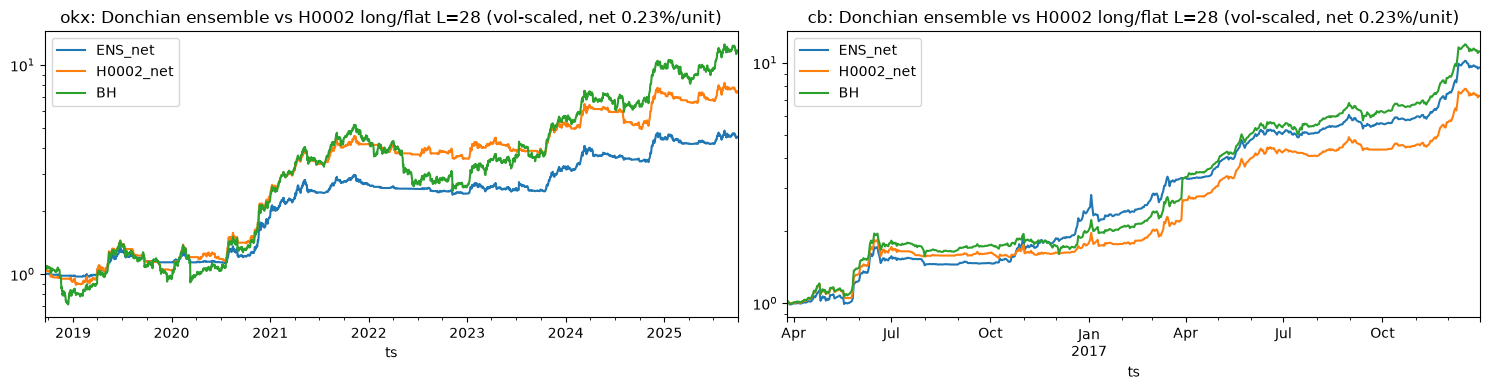

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, src in zip(axes, ['okx', 'cb']):
    s, e = (PERIODS['full'] if src == 'okx' else CB_PERIOD)
    for ver in ['ENS_net', 'H0002_net', 'BH']:
        (1 + PS[src][ver].loc[s:e].fillna(0)).cumprod().plot(ax=ax, logy=True, label=ver)
    ax.set_title(f'{src}: Donchian ensemble vs H0002 long/flat L=28 (vol-scaled, net 0.23%/unit)'); ax.legend()
plt.tight_layout()

## Collected p-values (raw + BH across this whole notebook)
Saved tidy to `results/pvals/H0012.csv` for a cross-hypothesis BH correction.

In [17]:
cols = ['test', 'source', 'coin', 'variant', 'period', 'horizon', 'n_event', 'diff', 'hac_t', 'hac_p', 'boot_lo', 'boot_hi']
PVALS = pd.concat([EV, EVP, BOP, QT, HR, PORT], ignore_index=True)[cols].rename(columns={'diff': 'effect'})
PVALS['diff'] = PVALS['effect']
PVALS['ci_lo'], PVALS['ci_hi'] = PVALS.boot_lo, PVALS.boot_hi
# < 5 events: a HAC p-value is meaningless (e.g. n=1 gives p~0) - keep the row and its mean, blank the inference
PVALS['low_n'] = PVALS.test.isin(['event', 'bo_partial']) & (PVALS.n_event < 5)
PVALS.loc[PVALS.low_n, ['hac_t', 'hac_p', 'boot_lo', 'boot_hi', 'ci_lo', 'ci_hi']] = np.nan
ok = PVALS.hac_p.notna()
PVALS['hac_p_adj'] = np.nan
PVALS.loc[ok, 'hac_p_adj'] = adjust_pvalues(PVALS.loc[ok, 'hac_p'].values)
print(PVALS.low_n.sum(), 'rows with n_event < 5 kept with blank p-values')
out = ROOT / 'results' / 'pvals'
out.mkdir(parents=True, exist_ok=True)
PVALS.to_csv(out / 'H0012.csv', index=False)
print(len(PVALS), 'rows,', ok.sum(), 'with p-values; min p_adj', PVALS.hac_p_adj.min().round(4), 'median p_adj', PVALS.hac_p_adj.median().round(4))
PVALS.sort_values('hac_p').head(15).round(4)

23 rows with n_event < 5 kept with blank p-values
384 rows, 361 with p-values; min p_adj 0.0019 median p_adj 0.5896


,test,source,coin,variant,period,horizon,n_event,effect,hac_t,hac_p,boot_lo,boot_hi,diff,ci_lo,ci_hi,low_n,hac_p_adj
375,portfolio,cb,PORT_CB,ENS,2015-2017,1,646,0.0038,4.3761,0.0000,0.0022,0.0053,0.0038,0.0022,0.0053,False,0.0019
379,portfolio,cb,PORT_CB,BH,2015-2017,1,646,0.0040,4.3473,0.0000,0.0023,0.0057,0.0040,0.0023,0.0057,False,0.0019
376,portfolio,cb,PORT_CB,ENS_net,2015-2017,1,646,0.0037,4.3222,0.0000,0.0022,0.0053,0.0037,0.0022,0.0053,False,0.0019
153,event,cb,LTC,BO_55,2015-2017,1,5,-0.0455,-3.9346,0.0001,-0.0644,-0.0220,-0.0455,-0.0644,-0.0220,False,0.0061
377,portfolio,cb,PORT_CB,H0002,2015-2017,1,646,0.0034,3.9310,0.0001,0.0019,0.0050,0.0034,0.0019,0.0050,False,0.0061
378,portfolio,cb,PORT_CB,H0002_net,2015-2017,1,646,0.0033,3.7747,0.0002,0.0018,0.0049,0.0033,0.0018,0.0049,False,0.0096
294,horse_race,okx,POOLED,HR:z28,full,7,11251,0.0150,3.5405,0.0004,NaN,NaN,0.0150,NaN,NaN,False,0.0183
333,horse_race,okx,POOLED,HR:z28,2022+,7,6810,0.0159,3.5246,0.0004,NaN,NaN,0.0159,NaN,NaN,False,0.0183
350,portfolio,okx,PORT,H0002,full,1,2569,0.0010,3.5053,0.0005,0.0005,0.0015,0.0010,0.0005,0.0015,False,0.0183
151,event,cb,LTC,BO_20,2015-2017,7,8,-0.1354,-3.4339,0.0006,-0.2145,-0.0656,-0.1354,-0.2145,-0.0656,False,0.0215


## Verdict vs pass criteria

In [18]:
ev = PVALS.query("test=='event' and source=='okx'")
full = ev.query("period=='full'")
crit_a = []
for v in [f'BO_{N}' for N in BO_NS]:
    for h, thr in [(7, 0.005), (28, 0.015)]:
        g = full.query('variant==@v and horizon==@h')
        sig = g[(g.effect > thr) & (g.hac_p_adj < 0.05) & (g.ci_lo > 0)].coin.tolist()
        sub = ev.query("variant==@v and horizon==@h and period!='full'").pivot_table(index='coin', columns='period', values='effect')
        both_pos = sub[(sub > 0).all(axis=1)].index.tolist()
        crit_a.append({'variant': v, 'horizon': h, 'threshold': thr, 'coins_pass': sig, 'n_pass': len(sig),
                       'coins_diff>thr': (g.effect > thr).sum(), 'coins_pos_both_subperiods': len(both_pos),
                       'min_p_adj': g.hac_p_adj.min()})
display(pd.DataFrame(crit_a))

hr = PVALS.query("test=='horse_race' and variant=='HR:NH365'")
per_coin = hr.query("coin in @COINS and period=='full'")
pooled = PVALS.query("test=='horse_race' and coin=='POOLED' and variant.str.startswith('HR:NH365')", engine='python')
evp = PVALS.query("test=='event_pooled'")
display(evp.pivot_table(index=['variant', 'horizon'], columns='period', values=['effect', 'hac_p_adj']).round(4))
display(PVALS.query("test=='port_diff'")[['source', 'variant', 'period', 'effect', 'hac_t', 'hac_p', 'ci_lo', 'ci_hi', 'hac_p_adj']].round(5))
print('(b) NH365 coef>0 & raw p<0.05 per coin (full):', per_coin[(per_coin.effect > 0) & (per_coin.hac_p < 0.05)].coin.tolist())
display(pooled[['variant', 'period', 'n_event', 'effect', 'hac_t', 'hac_p', 'hac_p_adj']].round(4))

sm_ = SUM.set_index(['source', 'period', 'variant'])
dep = {p: {'ENS_net_sharpe': sm_.loc[('okx', p, 'ENS_net'), 'sharpe'], 'H0002_net_sharpe': sm_.loc[('okx', p, 'H0002_net'), 'sharpe'],
           'ENS_maxdd': sm_.loc[('okx', p, 'ENS_net'), 'maxdd'], 'H0002_maxdd': sm_.loc[('okx', p, 'H0002_net'), 'maxdd'],
           'corr': sm_.loc[('okx', p, 'corr(ENS_net,H0002_net)'), 'ann_ret']} for p in PERIODS}
pd.DataFrame(dep).T.round(3)

,variant,horizon,threshold,coins_pass,n_pass,coins_diff>thr,coins_pos_both_subperiods,min_p_adj
0,BO_20,7,0.005,[],0,3,3,0.211329
1,BO_20,28,0.015,[],0,4,3,0.523467
2,BO_55,7,0.005,[],0,5,4,0.160741
3,BO_55,28,0.015,[],0,5,4,0.156307
4,BO_365,7,0.005,[],0,5,2,0.064285
5,BO_365,28,0.015,[],0,5,2,0.230901


effect                 hac_p_adj                
period          2018-2021   2022+    full 2018-2021   2022+    full
variant horizon                                                    
BO_20   1          0.0075 -0.0037  0.0011    0.5683  0.6615  0.8963
        7          0.0194  0.0090  0.0126    0.5235  0.6989  0.5228
        28         0.0564  0.0304  0.0376    0.5632  0.6114  0.5235
BO_365  1          0.0153  0.0155  0.0153    0.5896  0.5228  0.3385
        7          0.0833  0.0502  0.0630    0.1759  0.3933  0.1266
        28         0.1178  0.1176  0.1209    0.2230  0.5359  0.2511
BO_55   1          0.0138  0.0012  0.0066    0.5896  0.9212  0.6015
        7          0.0626  0.0332  0.0457    0.2511  0.3539  0.1356
        28         0.1806  0.0743  0.1209    0.2032  0.4586  0.1470

,source,variant,period,effect,hac_t,hac_p,ci_lo,ci_hi,hac_p_adj
353,okx,ENS-H0002:paired,full,-0.00031,-2.37888,0.01737,-0.00055,-0.00006,0.16074
354,okx,ENS-H0002:compare,full,-0.00031,-1.81080,0.07017,-0.00096,0.00033,0.30157
355,okx,ENS-H0002_net:paired,full,-0.00022,-1.69453,0.09016,-0.00046,0.00003,0.34627
356,okx,ENS-H0002_net:compare,full,-0.00022,-1.30144,0.19311,-0.00087,0.00042,0.52347
362,okx,ENS-H0002:paired,2018-2021,-0.00047,-2.44848,0.01435,-0.00085,-0.00009,0.15631
363,okx,ENS-H0002:compare,2018-2021,-0.00047,-1.76540,0.07750,-0.00149,0.00055,0.32157
364,okx,ENS-H0002_net:paired,2018-2021,-0.00041,-2.07852,0.03766,-0.00078,-0.00002,0.23044
365,okx,ENS-H0002_net:compare,2018-2021,-0.00041,-1.50695,0.13182,-0.00141,0.00061,0.44063
371,okx,ENS-H0002:paired,2022+,-0.00017,-0.94891,0.34267,-0.00047,0.00014,0.61140
372,okx,ENS-H0002:compare,2022+,-0.00017,-0.76168,0.44625,-0.00093,0.00062,0.69888


(b) NH365 coef>0 & raw p<0.05 per coin (full): []


,variant,period,n_event,effect,hac_t,hac_p,hac_p_adj
295,HR:NH365,full,11251,0.0003,0.1046,0.9167,0.9698
298,HR:NH365|lags35,full,11251,0.0003,0.0611,0.9513,0.9808
313,HR:NH365,2018-2021,4320,0.0011,0.1741,0.8618,0.9399
316,HR:NH365|lags28,2018-2021,4320,0.0011,0.1074,0.9145,0.9698
334,HR:NH365,2022+,6810,0.0041,1.2649,0.2059,0.5268
337,HR:NH365|lags35,2022+,6810,0.0041,0.7312,0.4647,0.7019


,ENS_net_sharpe,H0002_net_sharpe,ENS_maxdd,H0002_maxdd,corr
full,1.234,1.303,-0.198,-0.285,0.874
2018-2021,1.558,1.791,-0.161,-0.285,0.877
2022+,0.902,0.806,-0.161,-0.240,0.870


## Conclusion
**Verdict: REJECTED** (anchoring has no information beyond H0002; breakouts directionally positive but not significant; the Donchian ensemble is an H0002 re-skin with lower turnover and drawdown).

Against the Brief 1 pass criteria (p_adj = BH across all tests with >= 5 events in this notebook):
- **(a) Fresh breakouts:** 0/5 coins pass for any N/horizon. Diffs are mostly positive (BO_55 h7 > 0.5% on 5/5 coins, BO_365 h28 > 1.5% on 5/5) but per-coin n is tiny (BO_365: 6-15 events, BO_55: 18-26), best per-coin SOL BO_365 h7 +7.5% (raw p 0.003, p_adj 0.064, n=6). Pooled 5-coin stack: BO_365 h7 +6.3% (raw p 0.008, n=43), BO_55 h7 +4.6% (raw p 0.010, n=114), BO_55/365 h28 +12.1/+12.1% (raw p 0.012/0.046) - all p_adj 0.13-0.25, and 2022+ alone is not significant (raw p 0.09-0.22). One small-n sub-period cell (SOL BO_365 2022+ h7, n=5) has p_adj 0.042 but is outside the full-sample criterion. BO_20 ~ nothing. Partial regression BO + z28: BO coefficients keep their sign but stay insignificant (best raw p 0.027-0.035: ETH BO_55 h28, LTC BO_55 h28, SOL BO_365 h7) - every BO_55/BO_365 event already has R28 > 0.
- **(b) George-Hwang horse race:** NH_365 coefficient controlling for z28 and D is ~0 or negative on every coin (BTC t -1.1, LTC -1.2; XRP +1.6 best) and pooled (t +0.10 full; ~0 in 2018-2021, t +1.3 in 2022+; conservative lags35 t +0.06 full). Only z28 is significant in the pooled regression (t 3.5, p_adj 0.018). Quintiles of NH_365 are U-shaped (Q1 = far below the high also rebounds), Spearman negative on 3/5 coins - the 52-week-high anchor does not work in this 5-coin time series. MA distance D is positive for BTC/ETH/SOL (SOL Q5-Q1 h7 +9.3%, p_adj 0.048) but negative for XRP and is 0.8 correlated with z28.
- **Ensemble (deployability flag):** net (0.23%/unit) Sharpe 1.23 vs H0002 long/flat 1.30 (full), 1.56 vs 1.79 (2018-21), 0.90 vs 0.81 (2022+); max drawdown -20% vs -28%; turnover 4.3 vs 18.0 units/yr; paired daily difference ENS - H0002 net -0.022%/day (paired p 0.09, regression-based p 0.19). Daily-return correlation 0.87 (> 0.8) -> **flag fails**: not a distinct strategy. Coinbase 2015-2017: ensemble Sharpe 3.45 vs H0002 3.10 (bull market; B&H 3.45).

**Caveats:** 5-coin survivorship (today's large caps); OKX history from 2018-01 (NH_365 / BO_365 only from 2019-01; SOL from 2020-10, so 2018-2021 is short), coins highly correlated (pooled stack is not 5 independent samples; HAC lags scaled by n_coins); BO_365 events cluster in bull runs (0 in 2022); 23 sub-period cells with < 5 events have blank p-values; Spearman p ignores overlap; Coinbase 2015-2017 tiny event counts.

**Direction for a strategy:** do not build a separate anchoring/breakout strategy. The Donchian ensemble is worth testing as a *replacement/upgrade of the S0002 H0002 sleeve* (same return, ~30% smaller drawdown, ~4x less turnover - matters on perps/higher costs), or blending 50/50 with R28 long/flat; a pooled BO_55/BO_365 'breakout boost' overlay could be explored only with walk-forward validation.